<!-- d2l:prose id=conditional-md-1 fw=all -->

# Conditional Generation

The generators in that section and that section are *unconditional*: they draw random samples from the marginal data distribution $p(x)$ without any way to specify a desired class, text prompt, or input image. Shortly after the original GAN paper, @Mirza.Osindero.2014 introduced *conditional GANs* (cGANs) by feeding a conditioning variable $c$ to both the generator $G(z, c)$ and the discriminator $D(x, c)$.

In this section, we address three questions:

1. What objective does the conditional formulation optimize, and what does its optimal critic estimate?
2. How should the conditioning variable $c$ be incorporated into the generator and discriminator architectures?
3. How do we evaluate a conditional generator separately for condition alignment, sample fidelity, and within-class diversity?

We illustrate these concepts by training and evaluating a class-conditional generator on the 10 classes of CIFAR-10.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=conditional-md-2 fw=all -->

## The Conditional Objective

### The Optimal Conditional Critic

Let data–condition pairs $(x, c) \sim p(x, c)$ be drawn from the joint data distribution, where $c$ may be a discrete class label, a text embedding, or an image. To match the condition marginal $p(c)$, we sample $c \sim p(c)$ from the real data and generate $x' = G(z, c) \sim q(\cdot \mid c)$, inducing the generated joint distribution $q(x, c) = p(c)\,q(x \mid c)$. The conditional log-loss objective applies the classic binary log-loss formulation (that section) to the pairs $(x, c)$:

$$
\begin{aligned}
V(D) &= \mathbb{E}_{(x, c) \sim p}\big[\log \sigma(D(x, c))\big] \\
&\quad + \mathbb{E}_{c \sim p(c),\; x' \sim q(\cdot \mid c)}\big[\log \sigma(-D(x', c))\big].
\end{aligned}
$$

Because the pointwise optimization over $D(x, c)$ is identical to the unconditional derivation on the product space $\mathcal{X} \times \mathcal{C}$, the optimal conditional critic is the log ratio of the joint densities, from which the shared marginal $p(c)$ cancels:

$$
\begin{aligned}
D^\star(x, c)
&= \log \frac{p(x, c)}{q(x, c)}
= \log \frac{p(c)\, p(x \mid c)}{p(c)\, q(x \mid c)}
= \log \frac{p(x \mid c)}{q(x \mid c)} .
\end{aligned}
$$

Thus, for each condition $c$, the optimal critic computes the log density ratio between the conditional distributions $p(\cdot \mid c)$ and $q(\cdot \mid c)$. Substituting $D^\star(x, c)$ back into the equation yields the expected conditional Jensen–Shannon divergence:

$$
\begin{aligned}
\max_D V(D)
&= \mathbb{E}_{c \sim p(c)}\Big[\, 2\, \mathrm{JS}\big(p(\cdot \mid c),\, q(\cdot \mid c)\big) \Big] - 2 \log 2 .
\end{aligned}
$$

This attains its global minimum $-2\log 2$ if and only if $q(\cdot \mid c) = p(\cdot \mid c)$ for every condition $c$ with $p(c) > 0$.

### Conditional versus Marginal Matching

Matching every conditional slice $q(\cdot \mid c) = p(\cdot \mid c)$ is strictly stronger than matching the marginal image distribution $q(x) = p(x)$. For example, suppose a CIFAR-10 generator produces realistic images but shifts all class labels cyclically ($q(\cdot \mid c) = p(\cdot \mid c + 1)$). Because all 10 classes have equal prior probability $p(c) = 1/10$, its marginal image distribution $q(x)$ matches $p(x)$ exactly, achieving the minimum unconditional divergence $\mathrm{JS}(p(x), q(x)) = 0$. In the conditional objective the equation, however, every slice is compared against a mismatched class ($\mathrm{JS}(p(\cdot \mid c), p(\cdot \mid c+1)) \approx \log 2$), yielding a near-maximal conditional divergence (Exercise 1).

Conversely, note that each condition $c$ is weighted by its prior frequency $p(c)$ in the equation: a rare condition with probability $p(c) = \epsilon$ contributes at most $2\epsilon \log 2$ to the objective, so imbalanced datasets often require class-balanced sampling to prevent the generator from ignoring rare classes.

## Conditioning Architectures

### Three Conditioning Mechanisms

the figure illustrates the three primary ways to feed a condition $c$ into a generator or discriminator:

1. *Concatenation* [@Mirza.Osindero.2014] embeds $c$ into a vector $e_c$ and concatenates it with the latent vector $z$ (or broadcasts and concatenates it with spatial feature maps).
2. *Feature modulation* scales and shifts each channel of an intermediate feature map $h$ via learned functions of $c$: $a(c) \odot h + b(c)$. When $h$ is normalized first, this is *conditional batch normalization* [@De-Vries.Strub.Mary.ea.2017; @Brock.Donahue.Simonyan.2019] (or AdaIN / FiLM), injecting the condition at every resolution of the generator.
3. *Projection discriminator head* [@Miyato.Koyama.2018] takes the inner product of a class embedding $e_c$ with the discriminator's pooled feature vector $\phi(x)$ and adds an unconditional score $\psi_0(x)$.

![Three conditioning mechanisms for GANs. Left: concatenation appends an embedding $e_c$ to the input or feature map. Middle: feature modulation applies a condition-dependent channelwise scale and shift $a(c) \odot h + b(c)$. Right: the projection discriminator head computes $e_c^\top \phi(x) + \psi_0(x)$.](../img/mdl-gan-conditioning.svg)

Below, we implement `Modulate` with per-class scale and shift embedding tables initialized to $a(c) = 1$ and $b(c) = 0$ (the identity mapping), and verify that a gradient step on class 3 updates only row 3 of the embedding tables.

In [2]:
class Modulate(nn.Module):
    """Scale and shift each channel of h by a(c) and b(c), one row per class."""
    def __init__(self, num_classes, channels):
        super().__init__()
        self.a = nn.Embedding(num_classes, channels)
        self.b = nn.Embedding(num_classes, channels)
        nn.init.ones_(self.a.weight)   # a(c) = 1, b(c) = 0: the identity
        nn.init.zeros_(self.b.weight)

    def forward(self, h, c):
        return self.a(c)[:, :, None, None] * h + self.b(c)[:, :, None, None]

<!-- d2l:prose id=conditional-md-3 fw=all -->

Before running the layer, we can predict two things. At initialization the output must equal the input, whatever the class. And a gradient step on a batch that requests only class 3 (cat, in the CIFAR-10 order used below) must change row 3 of each table and no other, because an embedding lookup passes gradient only to the rows it read. The check takes one such step toward the toy target $2h + 1$.

In [3]:
torch.manual_seed(0)
mod = Modulate(10, 8)
h = torch.randn(10, 8, 4, 4)  # one feature map per class
with torch.no_grad():
    print('at initialization: max |out - h| =',
          float((mod(h, torch.arange(10)) - h).abs().max()))
a0, b0 = mod.a.weight.detach().clone(), mod.b.weight.detach().clone()
c3 = torch.full((10,), 3)  # a batch that requests class 3 only
loss = ((mod(h, c3) - (2 * h + 1)) ** 2).mean()
loss.backward()
torch.optim.SGD(mod.parameters(), lr=0.1).step()
rows = lambda w, w0: (w != w0).any(1).nonzero().flatten().tolist()
print('after one step on class 3: rows changed in a', rows(mod.a.weight, a0),
      'and in b', rows(mod.b.weight, b0))

at initialization: max |out - h| = 0.0
after one step on class 3: rows changed in a [3] and in b [3]


<!-- d2l:prose id=conditional-md-4 fw=all -->

### Deriving the Projection Head via Bayes' Rule

Applying Bayes' rule $p(x \mid c) = p(c \mid x)p(x)/p(c)$ to the numerator and denominator of the equation (with shared prior $p(c)$) decomposes the optimal conditional critic into two terms:

$$
\log \frac{p(x \mid c)}{q(x \mid c)}
\;=\; \log \frac{p(c \mid x)}{q(c \mid x)} + \log \frac{p(x)}{q(x)} .
$$

The first term measures *class alignment* (the log ratio of the real and generated class posteriors at $x$), while the second measures *unconditional sample realism*. If we model both class posteriors as softmax classifiers over a shared feature representation $\phi(x)$, namely $p(c \mid x) \propto \exp(u_c^\top \phi(x))$ and $q(c \mid x) \propto \exp(w_c^\top \phi(x))$, their log ratio is $(u_c - w_c)^\top \phi(x)$ plus a $c$-independent log-partition difference. Absorbing the log-partition difference and $\log(p(x)/q(x))$ into a single scalar head $\psi_0(x)$ and setting $e_c = u_c - w_c$ yields the *projection discriminator* of @Miyato.Koyama.2018 (Exercise 2; compare with the auxiliary classifier GAN in Exercise 6):

$$
D(x, c) \;=\; e_c^\top \phi(x) + \psi_0(x).
$$

## Class-Conditional Generation on CIFAR-10

We now train a class-conditional generator on the 50,000 labeled $32 \times 32$ training images of CIFAR-10 (5,000 per class, loaded via `d2l.load_cifar10_arrays`).

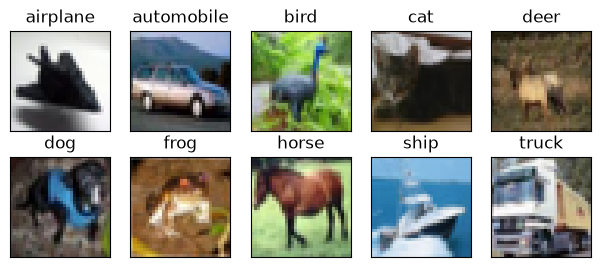

In [4]:
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']
device = d2l.try_gpu()
train_X, train_y, test_X, test_y = d2l.load_cifar10_arrays()
first = [int((train_y == c).nonzero()[0]) for c in range(10)]
d2l.show_images(train_X[first].cpu().permute(0, 2, 3, 1) / 2 + 0.5,
                num_rows=2, num_cols=5, titles=classes);

<!-- d2l:prose id=conditional-md-5 fw=all -->

### Conditional Generator and Projection Critic

We extend `d2l.Generator` and `d2l.Discriminator` (that section) at $32 \times 32$ resolution:

- `CondGenerator` passes a 64D unit-variance class embedding broadcast to $4 \times 4 \times 64$ into the generator's `extra` input slot (Exercise 4 compares this input concatenation with per-block `Modulate` layers).
- `ProjectionCritic` sums the $4 \times 4$ feature map `self.phi(x)` spatially to obtain $\phi(x)$ and evaluates $e_c^\top \phi(x) + \psi_0(\phi(x))$ (the equation), initializing $e_c = 0$ so the critic starts as an unconditional discriminator.

In [5]:
class CondGenerator(d2l.Generator):
    """The backbone generator with a class embedding as extra 4x4 maps."""
    def __init__(self, latent_dim, resolution, base_ch, embed_dim=64,
                 num_classes=10):
        super().__init__(latent_dim, resolution, base_ch, extra_ch=embed_dim)
        self.embed = nn.Embedding(num_classes, embed_dim)  # unit variance

    def forward(self, z, y):
        ec = self.embed(y)[:, :, None, None].expand(-1, -1, 4, 4)
        return super().forward(z, ec)

<!-- d2l:prose id=conditional-md-6 fw=all -->

`ProjectionCritic` implements the equation. The base class's `phi` returns the $4 \times 4$ feature map after the mixing convolution; summing it over positions gives $\phi(x)$. A linear head on $\phi(x)$ gives $\psi_0(x)$ and replaces the base head, which reads the flattened map, and a table holds one embedding $e_c$ per class. The table starts at zero, so the critic begins as an unconditional critic and learns the label term from the data.

In [6]:
class ProjectionCritic(d2l.Discriminator):
    """The backbone critic with a projection head: e_c . phi(x) + psi_0(x)."""
    def __init__(self, resolution, base_ch, num_classes=10):
        super().__init__(resolution, base_ch)
        width = self.mix.out_channels
        self.head = nn.Linear(width, 1)  # psi_0 on the pooled features
        d2l.fan_in_init(self.head)
        self.embed = nn.Embedding(num_classes, width)
        nn.init.zeros_(self.embed.weight)  # start as an unconditional critic

    def forward(self, x, y):
        phi = self.phi(x).sum(dim=(2, 3))  # sum over the 4x4 positions
        return (self.embed(y) * phi).sum(dim=1) + self.head(phi).squeeze(-1)

net_G, net_D = CondGenerator(100, 32, 256), ProjectionCritic(32, 64)
print(net_G(torch.zeros(2, 100), torch.zeros(2, dtype=torch.long)).shape)
print(net_D(torch.zeros(2, 3, 32, 32),
            torch.zeros(2, dtype=torch.long)).shape)

torch.Size([2, 3, 32, 32])
torch.Size([2])


<!-- d2l:prose id=conditional-md-7 fw=all -->

### Training with Same-Class Pairs

We train with `d2l.train_r3gan` (that section) for 15,000 steps using batch size 128 and gradient penalty weight $\gamma = 0.5$. In each minibatch, the generated images are conditioned on the exact class labels $y$ of the real minibatch, so the relativistic pairing loss $\log \sigma(D(x, c) - D(x', c))$ always compares a real image and a generated image of the *same* class $c$. Note that because comparisons are purely within-class, $D(x, c)$ is shift-invariant up to an independent additive constant $\zeta_c$ per class (Exercise 3); the logged held-out pairwise ranking accuracy $\hat P(D(x, c) > D(x', c))$ on 512 test pairs is invariant to these per-class shifts.

In [7]:
torch.manual_seed(0)  # the initialization
net_G = CondGenerator(100, 32, 256).to(device)
net_D = ProjectionCritic(32, 64).to(device)
gamma = 0.5
ema_G, history = d2l.train_r3gan(
    net_G, net_D, d2l.rpgan_loss_D, d2l.rpgan_loss_G, gamma, 15000, train_X,
    train_y, eval_images=test_X, eval_labels=test_y, eval_size=512,
    batch_size=128, seed=1)

<!-- d2l:prose id=conditional-md-8 fw=all -->

We average the logs over the last 5,000 steps, and the pair accuracy also over the first 2,000.

In [8]:
loss_D, loss_G, pen, acc = (np.mean(v[-5000 // 250:]) for v in (
    history['loss_D'], history['loss_G'], history['R1'] + history['R2'],
    history['accuracy']))
acc_early = history['accuracy'][history['step'] <= 2000].mean()
print(f'last 5,000 steps: critic loss {loss_D:.2f} (+ penalty '
      f'{gamma / 2 * pen:.3f}), generator loss {loss_G:.2f}, '
      f'pair accuracy {acc:.2f}')
print(f'first 2,000 steps: pair accuracy {acc_early:.2f}')

last 5,000 steps: critic loss 0.52 (+ penalty 0.062), generator loss 1.05, pair accuracy 0.79
first 2,000 steps: pair accuracy 0.83


<!-- d2l:prose id=conditional-md-9 fw=all -->

Plotting the full trajectories of `loss_D`, `loss_G`, and held-out `accuracy`
across all 15,000 steps shows how quickly the projection critic and conditional
generator settle into a steady game:

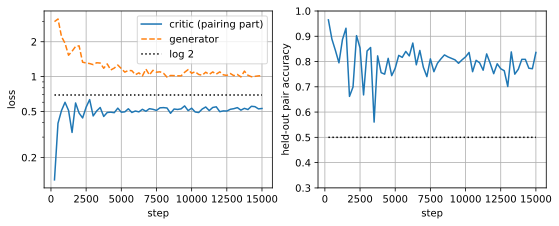

In [9]:
steps = history['step']
fig, axes = d2l.plt.subplots(1, 2, figsize=(9, 3.2))
d2l.plot(steps, [history['loss_D'], history['loss_G'],
                 np.full_like(steps, np.log(2))], 'step', 'loss',
         legend=['critic (pairing part)', 'generator', 'log 2'],
         fmts=('-', '--', 'k:'), yscale='log', axes=axes[0])
d2l.plot(steps, [history['accuracy'], np.full_like(steps, 0.5)], 'step',
         'held-out pair accuracy', ylim=[0.3, 1], fmts=('-', 'k:'),
         axes=axes[1]);

<!-- d2l:prose id=conditional-md-10 fw=all -->

After an initial transient, the critic's pairing loss stabilizes near $0.52$ (below $\log 2 \approx 0.69$) and held-out same-class pair ranking accuracy settles around $0.80$.

### Class-Conditioned Samples

Below, we generate 9 samples for each of the 10 CIFAR-10 classes from `ema_G`.

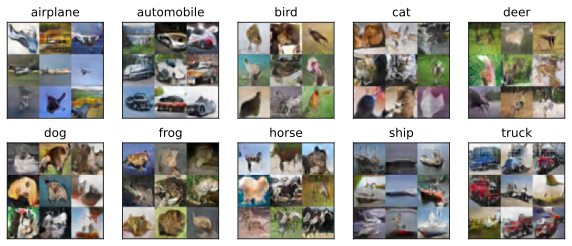

In [10]:
torch.manual_seed(42)
z = torch.randn(90, 100, device=device)
y = torch.arange(10, device=device).repeat_interleave(9)  # nine per class
with torch.no_grad():
    imgs = ema_G(z, y)
panels = [d2l.tile_images(imgs[9 * c:9 * (c + 1)], 3) for c in range(10)]
d2l.show_images(panels, 2, 5, titles=classes, scale=2);

<!-- d2l:prose id=conditional-md-11 fw=all -->

Each $3 \times 3$ panel reflects the visual characteristics of its requested class (e.g., blue skies and water for airplanes and ships, green foliage for frogs and deer, road backgrounds for automobiles and trucks) while varying pose and color across the 9 latent draws.

## Evaluating a Conditional Generator

A conditional generator can fail along three distinct axes:

1. *Wrong class* (poor condition alignment),
2. *Unrealistic images* (poor sample fidelity), or
3. *Lack of within-class diversity* (mode dropping within each class).

As summarized in the table, no single metric captures all three failure modes. We therefore combine a *referee classifier* (measuring class alignment) with marginal feature distances (FD and $\mathrm{MMD}^2$) and *per-class* $K$-NN precision and recall.

<!-- tbl-caption:Sensitivity of evaluation metrics to conditional generation failure modes. -->

| failure mode | class alignment | marginal FD, $\mathrm{MMD}^2$ | per-class precision | per-class recall |
|:--|:--|:--|:--|:--|
| wrong class | detects | blind | detects | detects |
| poor image fidelity | partial | detects | detects | partial |
| low within-class diversity | blind (may reward) | detects | blind (may reward) | detects |

### Referee Classifier and Class Alignment

We train the 3-block CIFAR-10 classifier `d2l.FeatureCNN` (that section) for 15 epochs as our independent referee (achieving $\sim 78\%$ test accuracy) and use both its class predictions and its 128D penultimate feature layer.

In [11]:
torch.manual_seed(0)
cnn = d2l.FeatureCNN(resolution=32).to(device)
d2l.train_feature_cnn(cnn, train_X, train_y, shift=4)
pred = d2l.batched(cnn, test_X).argmax(1)
cls_acc = [float((pred[test_y == c] == c).float().mean())
           for c in range(10)]
print(f'CIFAR-10 test accuracy: {float((pred == test_y).float().mean()):.3f}')

CIFAR-10 test accuracy: 0.779


<!-- d2l:prose id=conditional-md-12 fw=all -->

We generate 500 images per class from `ema_G` and compare the referee's classification accuracy on generated images (*alignment*) against its accuracy on real test images of each class.

In [12]:
def generate(seed, n=500):
    """n images of each class from the EMA generator, in class order."""
    torch.manual_seed(seed)
    z = torch.randn(10 * n, 100, device=device)
    y = torch.arange(10, device=device).repeat_interleave(n)
    with torch.no_grad():
        return torch.cat([ema_G(z_k, y_k) for z_k, y_k in
                          zip(z.split(1000), y.split(1000))])

raw = generate(7)
gen = raw.clamp(-1, 1)
yg = np.repeat(np.arange(10), 500)  # the requested classes
pred_gen = d2l.batched(cnn, gen).argmax(1).cpu().numpy()
align = [float((pred_gen[yg == c] == c).mean()) for c in range(10)]

<!-- d2l:prose id=conditional-md-13 fw=all -->

Tabulating `align` alongside the referee's accuracy `cls_acc` on real test
images for each of the 10 classes shows how well `ema_G` respects the requested
class label:

In [13]:
print(f'{"class":12s}{"alignment":>11s}{"real":>7s}{"gap":>7s}')
for name, a, r in zip(classes + ['mean'], align + [np.mean(align)],
                      cls_acc + [np.mean(cls_acc)]):
    print(f'{name:12s}{a:11.2f}{r:7.2f}{a - r:+7.2f}')

class         alignment   real    gap
airplane           0.80   0.78  +0.01
automobile         0.82   0.91  -0.09
bird               0.66   0.67  -0.01
cat                0.54   0.57  -0.03
deer               0.66   0.71  -0.05
dog                0.69   0.76  -0.06
frog               0.78   0.85  -0.07
horse              0.76   0.80  -0.05
ship               0.86   0.87  -0.01
truck              0.79   0.87  -0.08
mean               0.74   0.78  -0.04


<!-- d2l:prose id=conditional-md-14 fw=all -->

Mean class alignment across the 10 classes is $0.72\text{--}0.74$, only $4\text{--}6$ percentage points below the referee's accuracy on real CIFAR-10 test images ($0.78$).

### Fidelity and Within-Class Diversity

Next, we split the 1,000 test images per class into a 500-image reference set (`f_real`) and a 500-image real floor set (`f_real2`), and compute marginal FD and $\mathrm{MMD}^2$ (`d2l.fid_score`, `d2l.kid_score`) as well as per-class $K$-NN precision and recall (`d2l.precision_recall` with $K = 3$).

In [14]:
features = lambda imgs: d2l.batched(cnn.features, imgs).cpu().numpy()
out_of_range = float((raw.abs() > 1).float().mean())
idx = test_y.argsort(stable=True).reshape(10, 1000)  # row c: class c
f_real = features(test_X[idx[:, :500].flatten()])    # the reference
f_real2 = features(test_X[idx[:, 500:].flatten()])   # the floor
f_gen = features(gen)
f_gen2 = features(generate(8).clamp(-1, 1))          # a second draw
idx, pred_real = idx.cpu().numpy(), pred.cpu().numpy()

<!-- d2l:prose id=conditional-md-15 fw=all -->

We now compare the marginal feature distance (`d2l.fid_score`) and squared MMD
(`d2l.kid_score`) against the reference set `f_real` for the real test floor
`f_real2` and both generated draws (`f_gen`, `f_gen2`), and check the fraction
of raw pixel values `out_of_range`:

In [15]:
draws = {'real (the floor)': f_real2, 'generated': f_gen,
         'generated, second draw': f_gen2}
print(f'{"against the reference":24s}{"FD (CIFAR-CNN)":>16s}'
      f'{"MMD^2 (CIFAR-CNN)":>19s}')
for name, f in draws.items():
    print(f'{name:24s}{d2l.fid_score(f, f_real):16.2f}'
          f'{d2l.kid_score(f, f_real):19.3f}')
print(f'generated values outside [-1, 1]: {out_of_range:.3f}')

against the reference     FD (CIFAR-CNN)  MMD^2 (CIFAR-CNN)


real (the floor)                    0.15             -0.001


generated                           1.60              0.105


generated, second draw              1.65              0.108
generated values outside [-1, 1]: 0.010


<!-- d2l:prose id=conditional-md-16 fw=all -->

In FD the generated set lies ten to twelve times as far from the reference as the floor does, and the second draw moves FD by less than a tenth, so the distance belongs to the generator, not to the draw. In $\mathrm{MMD}^2$ the floor sits at zero within its noise and the generated set at about 0.11. About one raw value in a hundred lies outside $[-1, 1]$ before the clamp, so the clamp changes few pixels and hides little.

The distances fold every difference into one number. Per-class precision and recall separate two kinds of difference: generated images unlike any real image of their class, and real images unlike any generated one. Around each feature vector, draw a ball that reaches to its third-nearest neighbor in its own set (that section). *Precision* is the fraction of generated images of class $c$ that fall inside some real ball of class $c$, and *recall* is the fraction of real images of class $c$ that fall inside some generated ball. The cell computes both for each class against the reference, prints their means over classes and the worst class, and ends with the within-class feature variance, the variance of the features within each class averaged over features and classes.

In [16]:
by_class = lambda f: np.asarray(f).reshape(10, -1, f.shape[-1])

def pr_by_class(f):
    """Precision and recall of each class of f against the reference."""
    return np.array([d2l.precision_recall(r, g) for r, g in
                     zip(by_class(f_real), by_class(f))])

print(f'{"per class, k = 3":24s}{"precision":>10s}{"worst class":>17s}'
      f'{"recall":>8s}{"worst class":>17s}')
for name, f in draws.items():
    pr = pr_by_class(f)
    lo = pr.argmin(0)
    print(f'{name:24s}{pr[:, 0].mean():10.2f}{classes[lo[0]]:>12s}'
          f'{pr[lo[0], 0]:5.2f}{pr[:, 1].mean():8.2f}'
          f'{classes[lo[1]]:>12s}{pr[lo[1], 1]:5.2f}')
# Variance within each class, averaged over features and classes
cvar = lambda f: float(by_class(f).astype(np.float64).var(1).mean())
print(f'within-class feature variance: generated {cvar(f_gen):.3f}, '
      f'real {cvar(f_real):.3f}, the floor {cvar(f_real2):.3f}')

per class, k = 3         precision      worst class  recall      worst class
real (the floor)              0.85       truck 0.77    0.84        bird 0.80
generated                     0.90       truck 0.85    0.59       horse 0.52


generated, second draw        0.90       truck 0.84    0.59       truck 0.53
within-class feature variance: generated 0.174, real 0.217, the floor 0.212


<!-- d2l:prose id=conditional-md-17 fw=all -->

Per-class precision is actually *higher* for generated images ($0.90$) than for the real floor ($0.85$), indicating that generated features lie well inside the real class clusters, whereas per-class recall is substantially lower ($0.58$ vs. $0.83$, accompanied by a ~20% lower within-class feature variance), showing that the generator concentrates near the modes of each class rather than covering their full diversity.

### A Centroid-Prototype Baseline

To see why high alignment and high precision can mask a lack of diversity, we construct a *prototype baseline* by selecting the 100 real floor images per class whose features lie closest to their class centroid, and compare them against 100 random real floor images and 100 generated images per class.

In [17]:
floor = by_class(f_real2)  # test images 500-999 of each class
dist = ((floor - floor.mean(1, keepdims=True)) ** 2).sum(-1)
near = np.argsort(dist, axis=1)[:, :100]  # 100 distinct images per class
rows = np.arange(10)[:, None]
sets = {  # 100 images per class: features and the referee's predictions
    'real, random': (floor[:, :100], pred_real[idx[:, 500:600]]),
    'real, nearest centroid': (floor[rows, near],
                               pred_real[idx[:, 500:][rows, near]]),
    'generated': (by_class(f_gen)[:, :100],
                  pred_gen.reshape(10, 500)[:, :100])}
print(f'{"100 per class":24s}{"alignment":>10s}{"FD":>7s}{"MMD^2":>8s}'
      f'{"precision":>10s}{"recall":>8s}')
for name, (f, p) in sets.items():
    f = f.reshape(1000, -1)
    prec, rec = pr_by_class(f).mean(0)
    print(f'{name:24s}{(p == rows).mean():10.2f}'
          f'{d2l.fid_score(f, f_real):7.2f}{d2l.kid_score(f, f_real):8.3f}'
          f'{prec:10.2f}{rec:8.2f}')

100 per class            alignment     FD   MMD^2 precision  recall


real, random                  0.78   0.43  -0.003      0.85    0.85


real, nearest centroid        0.91   3.03   0.123      0.97    0.37


generated                     0.74   1.59   0.077      0.89    0.67


<!-- d2l:prose id=conditional-md-18 fw=all -->

As predicted in the table, the nearest-centroid prototypes achieve near-perfect alignment (about $0.9$, higher than random real images) and precision (about $0.97$), but suffer from severely degraded recall (under $0.4$ vs. about $0.85$) and worse FD (about $3$ vs. $0.43$) because their feature covariance is artificially contracted. BigGAN's *truncation trick* deliberately trades recall for higher precision and alignment by truncating the latent distribution $z$ toward zero (Exercise 5).

## Summary

Conditioning both the generator $G(z, c)$ and critic $D(x, c)$ on $c \sim p(c)$ yields the optimal slice-wise critic $D^\star(x, c) = \log(p(x \mid c)/q(x \mid c))$ and minimizes the expected conditional divergence $\mathbb{E}_{c \sim p(c)}[2\,\mathrm{JS}(p(\cdot \mid c), q(\cdot \mid c))] - 2\log 2$. Applying Bayes' rule decomposes $D^\star(x, c)$ into a class-alignment term $\log(p(c \mid x)/q(c \mid x))$ and an unconditional realism term $\log(p(x)/q(x))$, motivating the projection discriminator head $D(x, c) = e_c^\top \phi(x) + \psi_0(x)$ [@Miyato.Koyama.2018]. Evaluating a conditional generator requires separating condition alignment (via an independent referee classifier), sample fidelity (per-class precision), and within-class diversity (per-class recall and feature distances). Without a recall metric, a generator that emits only canonical class prototypes can achieve high classifier alignment and high precision while collapsing intra-class diversity.

## Exercises

1. [code] **Two Gaussian slices with known densities.** Let $c \in \{1, 2\}$ be equiprobable with $p(\cdot \mid 1) = \mathcal{N}(-2, 1)$ and $p(\cdot \mid 2) = \mathcal{N}(2, 1)$, and suppose $q(\cdot \mid 1) = \mathcal{N}(0, 1)$ while $q(\cdot \mid 2) = \mathcal{N}(2, 1)$.
    1. Compute the theoretical value the equation by 1D numerical quadrature.
    1. Train a small MLP critic on $(x, \text{one\_hot}(c))$ to maximize the equation, verify that its converged objective matches (a), and plot $D(x, c)$ against the exact log density ratio the equation for both slices.
    1. Now suppose the generator swaps the two classes: $q(\cdot \mid 1) = \mathcal{N}(2, 1)$ and $q(\cdot \mid 2) = \mathcal{N}(-2, 1)$. Compute both the conditional value the equation and the marginal unconditional value (ignoring $c$), and verify by training.

1. **Expressiveness of the projection discriminator head.** The derivation of the equation assumed a shared feature map $\phi(x)$ for both $p(c \mid x)$ and $q(c \mid x)$.
    1. If $p(c \mid x) \propto \exp(u_c^\top \phi_p(x))$ and $q(c \mid x) \propto \exp(w_c^\top \phi_q(x))$ use distinct feature maps, show that the resulting optimal critic still has the projection form the equation over the concatenated feature vector $(\phi_p(x), \phi_q(x))$.
    1. For $K$ discrete classes, show that *any* function $D(x, c)$ can be written in the form $e_c^\top \phi(x) + \psi_0(x)$ whenever $\dim(\phi(x)) \geq K$.

1. [short-code] **Using the projection critic as a classifier.** The trained projection critic `net_D` assigns ten scores $S_{ic} = D(x_i, c)$ to each image $x_i$.
    1. Use the equation to express $D^\star(x, c) - D^\star(x, c')$ in terms of $p(c \mid x)$ and $q(c \mid x)$. Why does $\arg\max_c D^\star(x, c)$ differ from the Bayes classifier $\arg\max_c p(c \mid x)$?
    1. Because same-class pairing leaves an arbitrary per-class shift $\zeta_c$ in $D(x, c)$, estimate $\hat\zeta_c$ as the mean critic score on generated images of class $c$, and compare the classification accuracy on `test_X` of raw $\arg\max_c S_{ic}$ versus shift-corrected $\arg\max_c (S_{ic} - \hat\zeta_c)$.
    1. Why must the shift-corrected critic accuracy approach random guessing ($1/10$) as $q(\cdot \mid c) \to p(\cdot \mid c)$?

1. [code] **Modulated generator versus input concatenation.** ● Build a conditional generator in which class information enters via a `Modulate` layer after every convolution block rather than input concatenation.
    1. At initialization ($a(c) = 1, b(c) = 0$), the modulated generator's output is independent of $c$. Trace how nonzero gradients with respect to $a(c)$ and $b(c)$ arise on the first generator step from the projection critic.
    1. Train both the modulated generator and `CondGenerator` for 4,000 steps across two seeds each, and compare their mean class alignment and per-class recall.

1. [code] **The truncation trick and the precision–recall trade-off.** The truncation trick [@Brock.Donahue.Simonyan.2019] samples each latent coordinate from a standard normal distribution truncated to $[-\tau, \tau]$.
    1. For a 100D latent vector and $\tau \in \{0.5, 1, 2\}$, compute the expected squared norm $\mathbb{E}[\|z\|^2]$ under truncated sampling and compare it with $\mathbb{E}[\|z\|^2] = 100$ during training.
    1. Evaluate `ema_G` under truncated sampling for $\tau \in \{0.5, 1, 2, \infty\}$ and report class alignment, per-class precision and recall, and FD against `f_real`. Verify that decreasing $\tau$ trades recall for higher alignment and precision, moving the generator toward the centroid-prototype regime.

   *Adapted from Simon Prince, [Understanding Deep Learning](https://udlbook.github.io/udlbook/), Problem 15.6.*

1. **Auxiliary Classifier GAN (AC-GAN) bias.** ● An AC-GAN [@Odena.Olah.Shlens.2017] trains an auxiliary classifier $C(c \mid x)$ and adds the cross-entropy $-\mathbb{E}_{c \sim p(c), x \sim q(\cdot \mid c)}[\log C(c \mid x)]$ to the generator loss.
    1. Show that this auxiliary generator loss equals

       $$\mathbb{E}_{x \sim q}\Big[H\big(q(\cdot \mid x)\big) + D_{\textrm{KL}}\big(q(\cdot \mid x) \,\|\, C(\cdot \mid x)\big)\Big].$$

    1. When $C(c \mid x) = p(c \mid x)$ and classes overlap ($H(p(\cdot \mid x)) > 0$), explain why minimizing this term encourages the generator to avoid overlapping regions of the data distribution, reducing within-class diversity compared to the projection discriminator (the equation).

[Discussions](https://d2l.discourse.group/t/36813)